# NB3 — El grafo de control paso a paso

Este cuaderno recorre el lazo táctico de `airsim-loop` **ejecutando el código de vuelo real** (`src/agents/graph.py` y los módulos que usa), sin AirSim. Sirve para explicar en la defensa qué calcula cada nodo y por qué el dron toma cada decisión.

| Sección | Qué muestra |
|---|---|
| §1 | La topología del `StateGraph`: cuatro nodos y una arista condicional |
| §2 | `DroneState`, el estado que circula entre nodos |
| §3 | Ciclos completos del grafo compilado con un cliente simulado en lugar de AirSim |
| §4 | `perception`: flujo óptico → derotación → FOE → TTC por celda → `ObstacleField` |
| §5 | Cómo `ObstacleField` decide «bloqueado» (umbrales calibrados) |
| §6 | `navigate`: las 8 reglas en orden, cada una disparada con un estado construido a mano |
| §7 | `action_to_command`: la cinemática de cada macro-acción |
| §8 | `motor`: ancla de altitud y gobernador de velocidad |
| §9 | Replay de `navigate` sobre una corrida real de la v4 y comparación ciclo a ciclo |

**Qué se reemplaza.** Solo los dos puntos de contacto con el simulador: `AirSimClient.capture()` (imagen + telemetría) y `AirSimClient.execute_velocity()` (comando). Todo lo demás es el código que vuela.

**Configuración offline.** Antes de importar el grafo se fija `STRATEGIC_SOURCE=off` y `DEADLOCK_STRATEGY=blind`. Con los valores de vuelo (`depth`) el grafo levanta en un hilo la red Depth Anything V2 sobre la GPU; acá se busca un resultado determinista y sin GPU. Las 8 reglas de `navigate` no cambian: la capa estratégica no comanda velocidades, solo propone sub-metas que el lazo externo inserta en el `WaypointTracker` (se explica en NB4). La única diferencia visible es la resolución de un deadlock: con `blind` es el escape vertical directo en lugar del barrido con profundidad.

**Cómo ejecutar:** kernel con el entorno `airsimenv`, directorio de trabajo `airsim-loop/`, *Run All*. No necesita AirSim, Ollama ni GPU. Usa una corrida de `airsim-runs/produccion/v4/` (§3, §4 y §9).

## §0 — Configuración

In [1]:
import os, sys, json, math, glob, re, collections, inspect
from pathlib import Path

# Configuracion offline (ver la explicacion de arriba). Debe ir ANTES de importar src.agents.
os.environ.setdefault('STRATEGIC_SOURCE', 'off')
os.environ.setdefault('DEADLOCK_STRATEGY', 'blind')
os.environ.setdefault('AGENT_ARM', 'slm')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / 'config' / '.env').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
LOOP = ROOT / 'airsim-loop'
if str(LOOP) not in sys.path:
    sys.path.insert(0, str(LOOP))
V4 = ROOT / 'airsim-runs' / 'produccion' / 'v4'
# Como experiments/runner.py: config/.env antes de importar src (los modulos leen su configuracion al importarse;
# sin esto el flujo correria a 320 px en lugar de los FLOW_DOWNSCALE_WIDTH=640 de vuelo).
from dotenv import load_dotenv
load_dotenv(ROOT / 'config' / '.env')

# Corrida de referencia (lote 6, citysim_pilot, brazo slm). Cambiar aqui para usar otra.
RUN_DIR = next((V4 / 'lote6_citysim_pilot' / 'citysim_pilot' / 'slm' / 'depth').glob('seed_233_*'))
RUN_STEM = RUN_DIR / RUN_DIR.name

plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_colwidth', 120)
print('repo:', ROOT)
print('corrida:', RUN_DIR.relative_to(ROOT))

repo: D:\TesisMCD\dronelm
corrida: airsim-runs\produccion\v4\lote6_citysim_pilot\citysim_pilot\slm\depth\seed_233_20261027T102920Z


In [2]:
from src.agents import graph as G
from src.agents.graph import build_workflow, _build_nodes, DroneState
from src.perception.flow_ttc import FlowTTCEstimator
from src.perception import flow_ttc as FT
from src.perception import obstacle_field as OF
from src.perception.obstacle_field import ObstacleField, Cell, SECTORS, BANDS, empty_field
from src.agents.action_map import action_to_command, VALID_ACTIONS
from src.navigation.speed_governor import SpeedGovernor

print('AGENT_ARM =', G.AGENT_ARM, '| FLOW_DOWNSCALE_WIDTH =', FT.FLOW_DOWNSCALE_WIDTH, 'px')
print('TTC_EVASION_THRESHOLD =', G.TTC_EVASION_THRESHOLD, 's   TTC_SAFE_THRESHOLD =', G.TTC_SAFE_THRESHOLD, 's')
print('FOV_BLOCKED_THRESHOLD =', G.FOV_BLOCKED_THRESHOLD, '   OPTICAL_MIN_ALT_M =', G._OPTICAL_MIN_ALT_M, 'm')

AGENT_ARM = slm | FLOW_DOWNSCALE_WIDTH = 640 px
TTC_EVASION_THRESHOLD = 3.2 s   TTC_SAFE_THRESHOLD = 4.6 s
FOV_BLOCKED_THRESHOLD = 0.6    OPTICAL_MIN_ALT_M = 4.5 m


## §1 — Topología: cuatro nodos y una arista condicional

`build_workflow()` arma el `StateGraph`. Cada invocación del grafo es **un ciclo del lazo rápido** (objetivo 5 Hz):

1. `capture` pide imagen y telemetría al cliente.
2. `degraded_router` (arista condicional): si AirSim no respondió, el ciclo va a `degraded_hover` (hover de seguridad, sin percepción); si respondió, a `perception`.
3. `perception` produce el `ObstacleField` del ciclo.
4. `navigate` decide la macro-acción con 8 reglas en orden fijo (§6).
5. `motor` aplica el ancla de altitud y el gobernador de velocidad y envía el comando.

El lazo lento (capa estratégica y barrido) no es un nodo: corre en un hilo propio (`DeliberationService`) y `navigate` lo consulta sin bloquear. Abajo, el grafo tal como lo compila LangGraph.

In [3]:
class ClienteNulo:
    # Cliente minimo para compilar el grafo: el ciclo no se ejecuta en esta celda.
    def capture(self):
        return None, {'source': 'none'}
    def execute_velocity(self, **kw):
        pass

app = build_workflow(ClienteNulo()).compile()
print(app.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	capture(capture)
	degraded_hover(degraded_hover)
	perception(perception)
	navigate(navigate)
	motor(motor)
	__end__([<p>__end__</p>]):::last
	__start__ --> capture;
	capture -.-> degraded_hover;
	capture -.-> perception;
	degraded_hover --> motor;
	navigate --> motor;
	perception --> navigate;
	motor --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



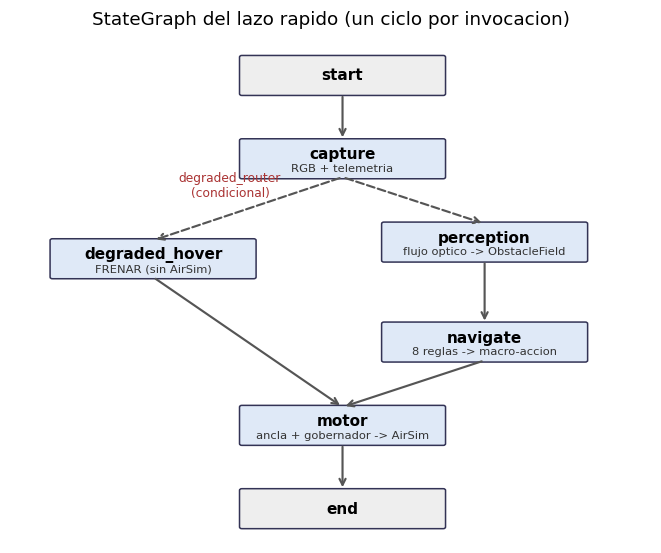

In [4]:
# Dibujo del mismo grafo con matplotlib (posiciones fijas).
pos = {'__start__': (0, 5), 'capture': (0, 4), 'degraded_hover': (-1.6, 2.8), 'perception': (1.2, 3.0),
       'navigate': (1.2, 1.8), 'motor': (0, 0.8), '__end__': (0, -0.2)}
desc = {'capture': 'RGB + telemetria', 'degraded_hover': 'FRENAR (sin AirSim)', 'perception': 'flujo optico -> ObstacleField',
        'navigate': '8 reglas -> macro-accion', 'motor': 'ancla + gobernador -> AirSim'}
g = app.get_graph()
fig, ax = plt.subplots(figsize=(7.5, 6))
for e in g.edges:
    (x0, y0), (x1, y1) = pos[e.source], pos[e.target]
    ax.annotate('', xy=(x1, y1 + 0.22), xytext=(x0, y0 - 0.22),
                arrowprops=dict(arrowstyle='->', lw=1.4, ls='--' if e.conditional else '-', color='#555'))
for n, (x, y) in pos.items():
    terminal = n.startswith('__')
    ax.add_patch(mpatches.FancyBboxPatch((x - 0.85, y - 0.22), 1.7, 0.44, boxstyle='round,pad=0.02',
                 fc='#eeeeee' if terminal else '#dfe9f7', ec='#335', lw=1))
    ax.text(x, y + (0.05 if n in desc else 0), n.strip('_'), ha='center', va='center', fontsize=10, weight='bold')
    if n in desc:
        ax.text(x, y - 0.12, desc[n], ha='center', va='center', fontsize=7.5, color='#333')
ax.text(-0.95, 3.55, 'degraded_router\n(condicional)', fontsize=8, color='#a33', ha='center')
ax.set_xlim(-2.8, 2.6); ax.set_ylim(-0.6, 5.5); ax.axis('off')
ax.set_title('StateGraph del lazo rapido (un ciclo por invocacion)')
plt.show()

## §2 — `DroneState`: el estado que circula entre nodos

`DroneState` es un `TypedDict`. LangGraph **descarta en silencio** toda clave que un nodo escriba y no esté declarada; por eso el código insiste en declararlas (el comentario de `_consecutive_escapes` documenta un defecto real de la v4 causado por eso). La tabla agrupa los campos tal como están comentados en `graph.py`.

In [5]:
src_graph = (LOOP / 'src' / 'agents' / 'graph.py').read_text(encoding='utf-8')
body = src_graph.split('class DroneState', 1)[1].split('\n\n\n', 1)[0]
rows, grupo = [], None
for line in body.splitlines()[3:]:
    s = line.strip()
    if s.startswith('#'):
        if not s.startswith('# ') or len(s) < 70:
            grupo = s.lstrip('# ').strip()
        continue
    m = re.match(r'(\w+):\s*(.+)', s)
    if m:
        rows.append({'grupo': grupo, 'campo': m.group(1), 'tipo': m.group(2)})
df_state = pd.DataFrame(rows)
assert set(df_state['campo']) == set(DroneState.__annotations__), 'la tabla no coincide con DroneState'
print(len(df_state), 'campos declarados')
display(df_state.groupby('grupo', sort=False)['campo'].apply(', '.join).to_frame('campos'))

57 campos declarados


,campos
grupo,
Percepcion y sensores,"rgb_image, prev_image, prev_telemetry, frame_history, frame_history_ts, telemetry, degraded, obstacle_field, estimat..."
Mision y guiado (los escribe el lazo externo),"waypoints, current_wp_index, target_waypoint, waypoint_guidance, mission_completed, evasion_stuck_cycles"
Decision y actuacion,"next_action, velocity_command, route, flight_status, active_maneuver, maneuver_cycles_left, maneuver_command, _hover..."
VLM: auditoria y canales hacia el lazo externo,"deliberations, last_deliberation, slm_request_id, _deliberation_pending, _pending_delib_prompt, _pending_delib_frame..."
Deadlock / barrido panoramico (deep_scan.py),"_escape_reset, _deadlock_cycles, _deadlock_event, _scan_phase, _scan_heading_index, _scan_frames, _scan_start_yaw_de..."
StallDetector (publicado para logging),"imu_jitter_level, imu_contact_event, blind_wall_event, _stopped_cycles, _wp_no_progress_cycles, _freeze_cycles"


## §3 — Ciclos completos del grafo compilado

Para ver el grafo funcionar de punta a punta se lo compila con un **cliente simulado** que reproduce una aproximación frontal: el dron avanza a 2 m/s hacia una superficie que está a 20 m. Cada fotograma es una foto real de la corrida de referencia ampliada por el factor exacto de esa aproximación (factor $D_0/(D_0 - v\,t)$), así que el **TTC verdadero de cada ciclo es conocido**: $\text{TTC}(t) = (D_0 - v\,t)/v$.

El lazo externo (lo que hace `main.py` alrededor de `app.invoke`) se reduce a lo mínimo: actualizar el guiado hacia un waypoint 100 m adelante y pasar el estado de salida como entrada del ciclo siguiente. El cliente no integra los comandos (lazo abierto): el objetivo es ver qué decide el grafo a medida que el TTC baja.

In [6]:
photos = sorted(RUN_DIR.glob('photo-*.png'))
FOTO = cv2.imread(str(photos[40]))
print(len(photos), 'fotos enviadas a la capa estrategica en esta corrida; se usa', photos[40].name, FOTO.shape)

def ampliar(im, s):
    # Ampliacion centrada por un factor s (aproximacion pura hacia el centro de la imagen).
    h, w = im.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), 0, s)
    return cv2.warpAffine(im, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

class ClienteSimulado:
    # Reemplaza a AirSimClient: capture() sirve la aproximacion; execute_velocity() guarda el comando.
    def __init__(self, base, d0=20.0, v=2.0, dt=0.2, alt=10.0, perder=()):
        self.base, self.d0, self.v, self.dt, self.alt = base, d0, v, dt, alt
        self.perder = set(perder)      # ciclos en que AirSim "no responde"
        self.k, self.comandos = 0, []
    def ttc_verdadero(self, k):
        return (self.d0 - self.v * k * self.dt) / self.v
    def capture(self):
        k = self.k; self.k += 1
        t = 1000.0 + k * self.dt
        x = self.v * k * self.dt
        tel = {'source': 'airsim', 'timestamp': t,
               'position': {'x': x, 'y': 0.0, 'z': -self.alt},
               'velocity': {'vx': self.v, 'vy': 0.0, 'vz': 0.0},
               'orientation': {'pitch': 0.0, 'roll': 0.0, 'yaw': 0.0},
               'imu_linear_acceleration': {'ax': 0.0, 'ay': 0.0, 'az': -9.8}}
        if k in self.perder:
            return None, {'source': 'none', 'timestamp': t}
        return ampliar(self.base, self.d0 / (self.d0 - x)), tel
    def execute_velocity(self, **cmd):
        self.comandos.append(cmd)

def guiado(x, wp_x=100.0, v=2.0):
    # Guiado nominal minimo: el WP esta adelante, sin error de rumbo (lo calcula WaypointTracker en vuelo).
    wp = {'x': wp_x, 'y': 0.0, 'z': -10.0, 'label': 'WP_DEMO'}
    d = wp_x - x
    return {'vx': v, 'vy': 0.0, 'vz': 0.0, 'yaw_rate': 0.0, 'target_wp': wp, 'distance': d, 'dist_xy': d,
            'bearing_err_deg': 0.0, 'ceiling_z': None, 'z_path_blocked': False, 'dz': 0.0, 'takeoff': False}

292 fotos enviadas a la capa estrategica en esta corrida; se usa photo-20261027T133019.894Z.png (720, 720, 3)


In [7]:
cli = ClienteSimulado(FOTO, perder={3})
app = build_workflow(cli).compile()
estado = {'waypoints': [{'x': 100.0, 'y': 0.0, 'z': -10.0, 'label': 'WP_DEMO'}], 'current_wp_index': 0}
filas = []
for k in range(42):
    x = cli.v * k * cli.dt
    estado['waypoint_guidance'] = guiado(x)          # lazo externo: guiado al WP
    estado = app.invoke(estado)                       # un ciclo del grafo
    f = estado.get('obstacle_field') or empty_field()
    cmd = cli.comandos[-1]
    sin_captura = estado['route'] == 'degraded'      # en degraded_hover no corre perception
    filas.append({'ciclo': k, 't_s': round(k * cli.dt, 1), 'TTC verdadero (s)': round(cli.ttc_verdadero(k), 2),
                  'fuente': '(sin captura)' if sin_captura else f.source,
                  'TTC centro (s)': None if sin_captura else round(f.sector_ttc('centro'), 2),
                  'centro bloq.': None if sin_captura else f.is_blocked('centro'),
                  'frac. bloq.': None if sin_captura else round(f.blocked_fraction(), 2),
                  'route': estado['route'], 'accion': estado['next_action'],
                  'vx': round(cmd['vx'], 2), 'vy': round(cmd['vy'], 2), 'yaw_rate': round(cmd['yaw_rate'], 1),
                  'tope vel.': estado.get('_speed_cap')})
df_ciclos = pd.DataFrame(filas)
display(df_ciclos)

,ciclo,t_s,TTC verdadero (s),fuente,TTC centro (s),centro bloq.,frac. bloq.,route,accion,vx,vy,yaw_rate,tope vel.
0,0,0.0,10.0,none,inf,False,0.00,reactive,MANTENER_RUMBO,2.0,0.0,0.0,NaN
1,1,0.2,9.8,flow,9.18,True,0.33,evasive,EVADIR_DERECHA,1.2,0.0,15.0,NaN
2,2,0.4,9.6,flow,inf,False,0.00,reactive,MANTENER_RUMBO,2.0,0.0,0.0,NaN
3,3,0.6,9.4,(sin captura),NaN,None,NaN,degraded,FRENAR,0.0,0.0,0.0,NaN
4,4,0.8,9.2,none,inf,False,0.00,reactive,MANTENER_RUMBO,2.0,0.0,0.0,NaN
5,5,1.0,9.0,flow,8.53,True,0.78,evasive,EVADIR_DERECHA,1.2,0.0,15.0,NaN
6,6,1.2,8.8,flow,8.28,True,0.89,evasive,EVADIR_DERECHA,1.2,0.0,15.0,NaN
7,7,1.4,8.6,flow,inf,False,0.00,reactive,MANTENER_RUMBO,2.0,0.0,0.0,NaN
8,8,1.6,8.4,flow,7.46,True,0.89,evasive,EVADIR_IZQUIERDA,1.2,0.0,-15.0,NaN
9,9,1.8,8.2,flow,inf,False,0.00,reactive,MANTENER_RUMBO,2.0,0.0,0.0,NaN


**Cómo leer la tabla.**

- **Ciclo 0:** no hay fotograma previo, el campo sale con fuente `none` y manda el guiado nominal (`reactive`).
- **Ciclo 3:** el cliente simula que AirSim no respondió. `degraded_router` desvía el ciclo a `degraded_hover` (`FRENAR`, ruta `degraded`) sin pasar por `perception`. En el ciclo 4 el fotograma previo es el que faltó, no hay par para el flujo y el campo vuelve a salir `none`. El flujo reaparece en el ciclo 5.
- **Bloqueo por ocupación desde lejos.** La superficie sintética llena todo el campo visual y toda la imagen se expande. La divergencia supera el umbral de ocupación desde el primer ciclo con flujo: el centro figura bloqueado y `navigate` evade (regla 7, segunda condición: `center_blocked`) mucho antes de que el TTC cruce los umbrales. El lado de la evasión alterna porque, en una superficie uniforme, las ocupaciones izquierda y derecha son casi iguales. `evasive_node` no compromete la maniobra, la vuelve a elegir cada ciclo.
- **Giro de 90°.** Cuando el TTC del centro baja de `TTC_SAFE_THRESHOLD` con el centro bloqueado y más del 60 % de las celdas bloqueadas, `navigate` gira 90° (ruta `girar_90`). Ese giro sí queda comprometido 5 ciclos (regla 3, ruta `evasive` con acción `GIRAR_90`).
- **TTC estimado.** Sigue al verdadero por debajo: el TTC de cada celda es el percentil 20 de sus píxeles (§4). Los ciclos con TTC infinito y fuente `flow` son pares en que el FOE no pasó el control de calidad.
- **Gobernador.** La columna «tope vel.» muestra al gobernador de velocidad del `motor`. Con el frente bloqueado (fracción ≥ 0.99) limita el crucero a 1 m/s (§8).

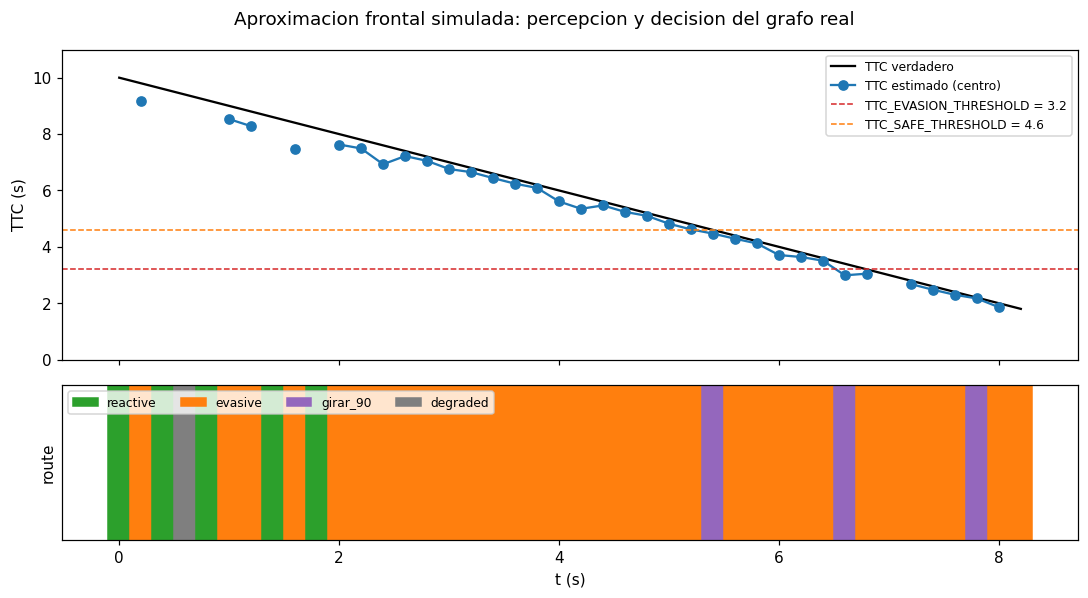

In [8]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
d = df_ciclos[df_ciclos['fuente'] == 'flow']
a1.plot(df_ciclos['t_s'], df_ciclos['TTC verdadero (s)'], 'k-', label='TTC verdadero')
a1.plot(d['t_s'], d['TTC centro (s)'].replace(np.inf, np.nan), 'o-', color='#1f77b4', label='TTC estimado (centro)')
a1.axhline(G.TTC_EVASION_THRESHOLD, color='#d62728', ls='--', lw=1, label=f'TTC_EVASION_THRESHOLD = {G.TTC_EVASION_THRESHOLD}')
a1.axhline(G.TTC_SAFE_THRESHOLD, color='#ff7f0e', ls='--', lw=1, label=f'TTC_SAFE_THRESHOLD = {G.TTC_SAFE_THRESHOLD}')
a1.set_ylabel('TTC (s)'); a1.set_ylim(0, 11); a1.legend(fontsize=8)
colores = {'reactive': '#2ca02c', 'evasive': '#ff7f0e', 'girar_90': '#9467bd', 'degraded': '#7f7f7f', 'tactical': '#d62728'}
for _, r in df_ciclos.iterrows():
    a2.axvspan(r['t_s'] - 0.1, r['t_s'] + 0.1, color=colores.get(r['route'], '#ccc'))
a2.legend(handles=[mpatches.Patch(color=c, label=k) for k, c in colores.items() if k in set(df_ciclos['route'])],
          fontsize=8, ncol=5, loc='upper left')
a2.set_yticks([]); a2.set_xlabel('t (s)'); a2.set_ylabel('route')
fig.suptitle('Aproximacion frontal simulada: percepcion y decision del grafo real')
plt.tight_layout(); plt.show()

## §4 — `perception`: del par de fotogramas al `ObstacleField`

`FlowTTCEstimator.estimate()` (`src/perception/flow_ttc.py`) hace cinco pasos. Acá se ejecutan uno por uno sobre el mismo par sintético, con un TTC verdadero de 2 s, usando los métodos internos del estimador.

1. **Flujo óptico denso** (DIS de OpenCV) sobre las dos imágenes en gris, reducidas a `FLOW_DOWNSCALE_WIDTH` px de ancho (640 en vuelo).
2. **Derotación.** Se resta el flujo que produce la rotación propia del dron entre fotogramas (Δpitch, Δyaw, Δroll de la telemetría o del giróscopo). Si la rotación supera `FLOW_MAX_ROTATION_DEG`, no se estima: se sostiene el último campo válido (*holdover*) hasta `FLOW_HOLDOVER_MAX_FRAMES` ciclos, o el campo sale `degraded`.
3. **FOE** (*focus of expansion*) por mínimos cuadrados ponderados: el punto desde el que diverge el flujo traslacional.
4. **TTC por píxel**: $\text{TTC} = \lVert p - \text{FOE}\rVert \cdot \Delta t / \lVert v_\text{trans}\rVert$, en segundos reales (Δt de la telemetría, no el período nominal).
5. **Agregación por celda** (3 sectores × 3 bandas): percentil `TTC_AGGREGATION_PERCENTILE` (20) del TTC, divergencia media → ocupación, y confianza = fracción de píxeles válidos × confianza del FOE.

imagen 720x720 -> 640x640; focal 492.4 px; |flujo| mediano 25.14 px, p95 36.70 px


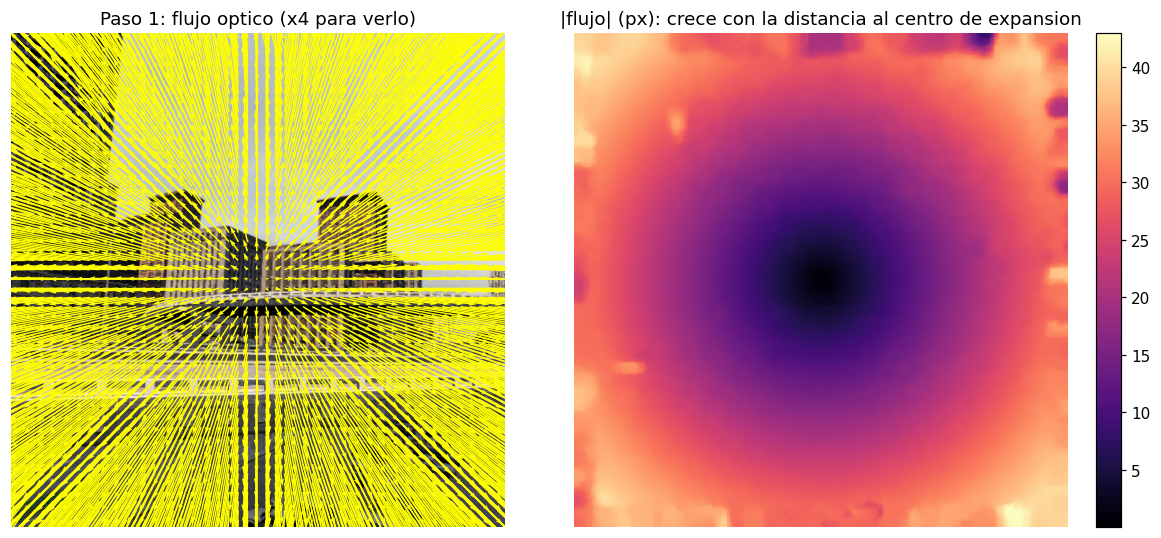

In [9]:
DT, TTC_REAL = 0.2, 2.0
prev, cur = FOTO, ampliar(FOTO, 1 + DT / TTC_REAL)
est = FlowTTCEstimator()

# Paso 1: flujo denso a la resolucion reducida
g0, g1 = (cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in (prev, cur))
esc = min(1.0, FT.FLOW_DOWNSCALE_WIDTH / g1.shape[1])
size = (int(g1.shape[1] * esc), int(g1.shape[0] * esc))
g0s, g1s = (cv2.resize(g, size, interpolation=cv2.INTER_AREA) for g in (g0, g1))
flow = est._compute_flow(g0s, g1s)
h, w = flow.shape[:2]
fx, fy, cx, cy = FT.CAMERA_FX * esc, FT.CAMERA_FY * esc, w / 2, h / 2
mag = np.linalg.norm(flow, axis=2)
print(f'imagen {g1.shape[1]}x{g1.shape[0]} -> {w}x{h}; focal {fx:.1f} px; |flujo| mediano {np.median(mag):.2f} px, p95 {np.quantile(mag, .95):.2f} px')

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(cv2.cvtColor(cv2.resize(prev, size), cv2.COLOR_BGR2RGB))
st = 12
yy, xx = np.mgrid[st // 2:h:st, st // 2:w:st]
ax[0].quiver(xx, yy, flow[yy, xx, 0], flow[yy, xx, 1], color='yellow', angles='xy', scale_units='xy', scale=0.25, width=0.003)
ax[0].set_title('Paso 1: flujo optico (x4 para verlo)')
im1 = ax[1].imshow(mag, cmap='magma'); plt.colorbar(im1, ax=ax[1], fraction=0.046)
ax[1].set_title('|flujo| (px): crece con la distancia al centro de expansion')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Paso 2, derotación.** Para verla hace falta rotación: se genera un par con un giro de yaw puro, sin traslación, mediante la homografía exacta $H = K R K^{-1}$. Con la convención de la telemetría (Δyaw > 0 es un giro a la derecha, la escena se corre a la izquierda), la derotación debería dejar un flujo residual casi nulo. Sin traslación no hay evidencia de obstáculo: el estimador tiene que devolver un campo sin confianza, no falsos bloqueos.

In [10]:
def girar(im, dyaw_rad, f=FT.CAMERA_FX):
    # Fotograma visto despues de girar dyaw (convencion de la telemetria: > 0 = derecha). Homografia K R K^-1.
    hh, ww = im.shape[:2]
    K = np.array([[f, 0, ww / 2], [0, f, hh / 2], [0, 0, 1.0]])
    a = -dyaw_rad
    R = np.array([[math.cos(a), 0, math.sin(a)], [0, 1, 0], [-math.sin(a), 0, math.cos(a)]])
    return cv2.warpPerspective(im, K @ R @ np.linalg.inv(K), (ww, hh), borderMode=cv2.BORDER_REFLECT)

dyaw = math.radians(1.5)
gr = cv2.resize(cv2.cvtColor(girar(FOTO, dyaw), cv2.COLOR_BGR2GRAY), size, interpolation=cv2.INTER_AREA)
flow_rot = est._compute_flow(g0s, gr)
res = {}
for nombre, dy in (('sin derotar', 0.0), ('derotado con +dyaw (telemetria)', dyaw), ('derotado con signo opuesto', -dyaw)):
    ft_ = est._derotate(flow_rot, 0.0, dy, 0.0, fx, fy, cx, cy)
    m = np.linalg.norm(ft_, axis=2)
    res[nombre] = {'|flujo| mediano (px)': round(float(np.median(m)), 3),
                   'pixeles validos (> piso de ruido)': f'{np.mean(m > FT.FLOW_NOISE_FLOOR_PX):.1%}'}
display(pd.DataFrame(res).T)

t0 = {'timestamp': 0.0, 'orientation': {'pitch': 0, 'roll': 0, 'yaw': 0.0}}
t1 = {'timestamp': DT, 'orientation': {'pitch': 0, 'roll': 0, 'yaw': dyaw}}
f_rot = FlowTTCEstimator().estimate(girar(FOTO, dyaw), FOTO, t1, t0)
print('estimate() con giro puro de 1.5 deg -> fuente:', f_rot.source, '| foe_confidence:', round(f_rot.foe_confidence, 3),
      '| fraccion bloqueada:', f_rot.blocked_fraction())
f_rot3 = FlowTTCEstimator().estimate(girar(FOTO, math.radians(4)), FOTO, {**t1, 'orientation': {'pitch': 0, 'roll': 0, 'yaw': math.radians(4)}}, t0)
print(f'estimate() con giro de 4 deg (> FLOW_MAX_ROTATION_DEG = {FT.FLOW_MAX_ROTATION_DEG}) -> fuente:', f_rot3.source)

,|flujo| mediano (px),pixeles validos (> piso de ruido)
sin derotar,14.298,100.0%
derotado con +dyaw (telemetria),0.191,19.6%
derotado con signo opuesto,28.64,100.0%


estimate() con giro puro de 1.5 deg -> fuente: flow | foe_confidence: 0.136 | fraccion bloqueada: 0.0
estimate() con giro de 4 deg (> FLOW_MAX_ROTATION_DEG = 2.0) -> fuente: degraded


**Pasos 3 a 5: FOE, TTC por píxel y celdas** sobre el par de aproximación pura (TTC verdadero 2 s). El FOE se obtiene resolviendo el sistema normal 2×2: para cada vector, la recta que lo contiene debe pasar por el FOE ($n \cdot (\text{FOE} - p) = 0$, con $n$ la normal al vector), ponderado por su módulo.

FOE estimado = (322.0, 316.9) px; centro de la imagen = (320, 320); foe_confidence = 0.30
TTC por pixel: mediana 2.01 s (verdadero 2.0 s)


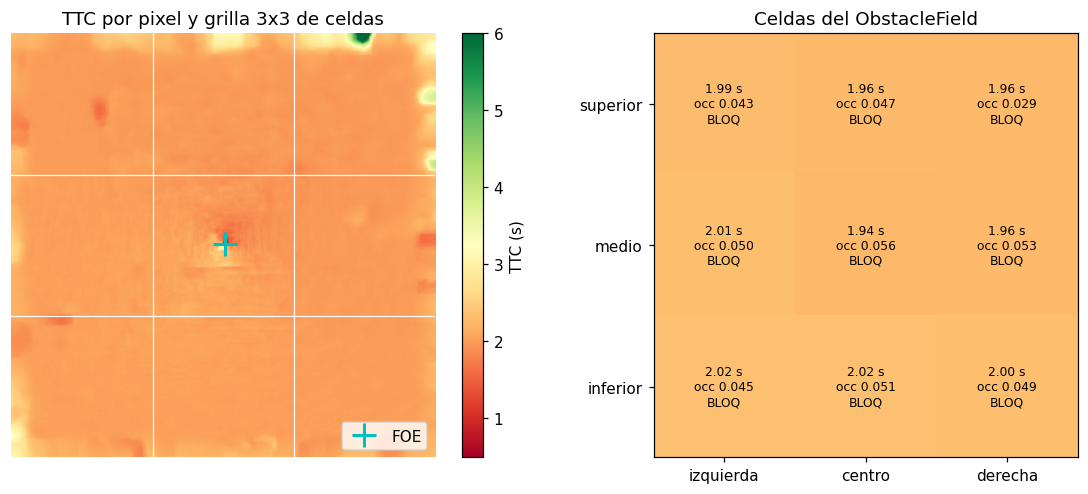

,sector,banda,TTC p20 (s),divergencia (1/s),ocupacion,confianza,bloqueada
0,izquierda,superior,1.99,0.76,0.043,0.3,True
1,izquierda,medio,2.01,0.90,0.050,0.3,True
2,izquierda,inferior,2.02,0.81,0.045,0.3,True
3,centro,superior,1.96,0.83,0.047,0.3,True
4,centro,medio,1.94,1.00,0.056,0.3,True
5,centro,inferior,2.02,0.91,0.051,0.3,True
6,derecha,superior,1.96,0.51,0.029,0.3,True
7,derecha,medio,1.96,0.94,0.053,0.3,True
8,derecha,inferior,2.00,0.87,0.049,0.3,True


In [11]:
flow_t = est._derotate(flow, 0.0, 0.0, 0.0, fx, fy, cx, cy)       # sin rotacion: queda igual
mag_t = np.linalg.norm(flow_t, axis=2)
valid = mag_t > FT.FLOW_NOISE_FLOOR_PX
foe, foe_conf = est._estimate_foe(flow_t, mag_t, valid, cx, cy)
print(f'FOE estimado = ({foe[0]:.1f}, {foe[1]:.1f}) px; centro de la imagen = ({cx:.0f}, {cy:.0f}); foe_confidence = {foe_conf:.2f}')

ys, xs = np.mgrid[0:h, 0:w].astype(np.float32)
ttc_map = np.where(valid, np.hypot(xs - foe[0], ys - foe[1]) * DT / np.maximum(mag_t, 1e-6), np.inf)
print(f'TTC por pixel: mediana {np.median(ttc_map[np.isfinite(ttc_map)]):.2f} s (verdadero {TTC_REAL} s)')

f_demo = FlowTTCEstimator().estimate(cur, prev, {'timestamp': DT, 'orientation': {'pitch': 0, 'roll': 0, 'yaw': 0}},
                                     {'timestamp': 0.0, 'orientation': {'pitch': 0, 'roll': 0, 'yaw': 0}})
tabla = pd.DataFrame([{'sector': c.sector, 'banda': c.band, 'TTC p20 (s)': round(c.ttc_s, 2), 'divergencia (1/s)': round(c.divergence, 2),
                       'ocupacion': round(c.occupancy, 3), 'confianza': round(c.confidence, 3), 'bloqueada': c.is_blocked()}
                      for c in f_demo.cells.values()])

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
im = ax[0].imshow(np.clip(ttc_map, 0, 6), cmap='RdYlGn'); plt.colorbar(im, ax=ax[0], fraction=0.046, label='TTC (s)')
ax[0].plot(*foe, 'c+', ms=16, mew=2, label='FOE'); ax[0].legend(loc='lower right')
for k in (1, 2):
    ax[0].axvline(k * w / 3, color='w', lw=0.8); ax[0].axhline(k * h / 3, color='w', lw=0.8)
ax[0].set_title('TTC por pixel y grilla 3x3 de celdas'); ax[0].axis('off')
piv = tabla.pivot(index='banda', columns='sector', values='TTC p20 (s)').loc[list(BANDS), list(SECTORS)]
ax[1].imshow(piv.values, cmap='RdYlGn', vmin=0, vmax=6)
for i in range(3):
    for j in range(3):
        b = tabla[(tabla.banda == BANDS[i]) & (tabla.sector == SECTORS[j])].iloc[0]
        ax[1].text(j, i, f"{b['TTC p20 (s)']:.2f} s\nocc {b['ocupacion']:.3f}\n{'BLOQ' if b['bloqueada'] else 'libre'}", ha='center', va='center', fontsize=8)
ax[1].set_xticks(range(3), SECTORS); ax[1].set_yticks(range(3), BANDS); ax[1].set_title('Celdas del ObstacleField')
plt.tight_layout(); plt.show()
display(tabla)

**Observación sobre la confianza del FOE.** `_estimate_foe` refina el FOE con un recorte de *outliers*: cuenta como *inlier* el vector cuyo ángulo con la recta **p → FOE** es menor que `FOE_OUTLIER_ANGLE_RAD`. En una aproximación pura el flujo traslacional apunta **desde** el FOE (sentido FOE → p), con un ángulo de ~180° respecto de esa recta. La celda siguiente cuenta los *inliers* con las dos orientaciones. Con muy pocos *inliers* el estimador toma el camino de «FOE poco confiable» y topa `foe_confidence` en 0.3. La confianza de cada celda (fracción válida × 0.3) queda entonces por debajo de `OBSTACLE_MIN_CONFIDENCE_TTC` (0.35), de modo que el TTC **por sí solo** no marca una celda bloqueada: la marca la ocupación derivada de la divergencia. En la corrida de referencia `foe_confidence` supera 0.3 en una minoría de los ciclos con flujo (se mide abajo). Este cuaderno lo documenta tal como está en el código de vuelo con el que se produjeron los resultados de la v4.

In [12]:
idx = np.where(valid)
dpx, dpy = foe[0] - xs[idx], foe[1] - ys[idx]
vx_, vy_, vm_ = flow_t[..., 0][idx], flow_t[..., 1][idx], mag_t[idx]
cos_pf = (dpx * vx_ + dpy * vy_) / (np.hypot(dpx, dpy) * vm_ + 1e-6)
ang = np.arccos(np.clip(cos_pf, -1, 1))
print(f'vectores validos: {idx[0].size}')
print(f'inliers segun el codigo (angulo con p->FOE < {FT.FOE_OUTLIER_ANGLE_RAD} rad): {int(np.sum(ang < FT.FOE_OUTLIER_ANGLE_RAD))}')
print(f'vectores alineados con FOE->p (expansion): {int(np.sum(np.pi - ang < FT.FOE_OUTLIER_ANGLE_RAD))}')

fc = []
with open(f'{RUN_STEM}.jsonl', encoding='utf-8') as fh:
    for line in fh:
        of = json.loads(line)['state'].get('obstacle_field') or {}
        if of.get('source') == 'flow':
            fc.append(float(of.get('foe_confidence') or 0.0))
fc = np.array(fc)
print(f'\ncorrida de referencia: {fc.size} ciclos con fuente flow; foe_confidence == 0.3 en {np.mean(np.isclose(fc, 0.3)):.1%}, '
      f'> 0.3 en {np.mean(fc > 0.3):.1%}, mediana {np.median(fc):.3f}')

vectores validos: 409572
inliers segun el codigo (angulo con p->FOE < 0.35 rad): 0
vectores alineados con FOE->p (expansion): 407448



corrida de referencia: 751 ciclos con fuente flow; foe_confidence == 0.3 en 6.7%, > 0.3 en 7.6%, mediana 0.034


In [13]:
# Exactitud del TTC estimado frente al verdadero en aproximaciones puras (sector centro, banda media)
filas = []
for ttc_v in (1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0):
    f_ = FlowTTCEstimator().estimate(ampliar(FOTO, 1 + DT / ttc_v), FOTO,
                                     {'timestamp': DT, 'orientation': {'pitch': 0, 'roll': 0, 'yaw': 0}},
                                     {'timestamp': 0.0, 'orientation': {'pitch': 0, 'roll': 0, 'yaw': 0}})
    c = f_.cells[('centro', 'medio')]
    filas.append({'TTC verdadero (s)': ttc_v, 'flujo en el borde (px)': round((1 + DT / ttc_v - 1) * size[0] / 2, 1),
                  'TTC estimado centro (s)': round(c.ttc_s, 2), 'foe_confidence': round(f_.foe_confidence, 3), 'ocupacion': round(c.occupancy, 3),
                  'confianza celda': round(c.confidence, 3), 'centro bloqueado': f_.is_blocked('centro'),
                  'fraccion bloqueada': round(f_.blocked_fraction(), 2)})
display(pd.DataFrame(filas))

,TTC verdadero (s),flujo en el borde (px),TTC estimado centro (s),foe_confidence,ocupacion,confianza celda,centro bloqueado,fraccion bloqueada
0,1.0,64.0,0.95,0.001,0.110,0.001,False,0.00
1,1.5,42.7,1.47,0.001,0.075,0.001,False,0.00
2,2.0,32.0,1.94,0.300,0.056,0.300,True,1.00
3,3.0,21.3,2.79,0.300,0.038,0.300,True,1.00
4,4.0,16.0,3.80,0.002,0.028,0.002,False,0.00
5,6.0,10.7,5.74,0.300,0.019,0.298,True,0.89
6,8.0,8.0,7.72,0.004,0.014,0.004,False,0.00
7,12.0,5.3,11.11,0.001,0.009,0.001,False,0.00


Con el ancho de vuelo (640 px), el TTC estimado sigue de cerca al verdadero, apenas por debajo porque cada celda toma el percentil 20 de sus píxeles. Lo errático es la **confianza**, que es la consecuencia práctica de la observación anterior:

- En las filas con `foe_confidence` cerca de 0.3, el estimador tomó el camino de «pocos inliers». La celda queda con confianza 0.3 y la bloquea la ocupación, no el TTC.
- En las filas con `foe_confidence` casi nula, unos pocos *inliers* accidentales (≥ 30) llevaron al camino «robusto», cuya confianza (*inliers* / píxeles × 3) queda cerca de cero. La celda no bloquea aunque el TTC sea bajo y la ocupación supere el umbral.

Qué fila cae en cada caso depende de detalles del par de imágenes, no del riesgo. Sin flujo suficiente, el campo devuelve confianza baja y TTC infinito, sin un valor inventado que oculte la falta de señal. La validación contra la profundidad del simulador y la derivación de los umbrales por Youden están en NB5 §10 y en el informe, cap. 7; el efecto en vuelo de corregir la prueba de *inliers*, en el cap. 7 §7.7.

## §5 — Cuándo una celda está «bloqueada»

`Cell.is_blocked()` combina tres umbrales de `config/.env`, todos calibrados (cap. 7 del informe):

1. Sin confianza suficiente (`OBSTACLE_MIN_CONFIDENCE`) la celda **no** puede bloquear: ausencia de evidencia no es obstáculo (pero el gobernador de velocidad sí la penaliza, §8).
2. Ocupación ≥ `OBSTACLE_OCCUPANCY_BLOCKED` (0.011, Youden sobre la ROC de ocupación, AUC 0.87): bloqueada.
3. Si no, el TTC solo bloquea con una confianza mayor (`OBSTACLE_MIN_CONFIDENCE_TTC`) y TTC ≤ `OBSTACLE_TTC_BLOCKED_S`.

El sector se agrega por columna: bloqueado si alguna de sus tres celdas lo está; su TTC es el mínimo de las celdas con confianza. `blocked_fraction()` es la fracción de las 9 celdas bloqueadas: la usa `navigate` para distinguir un obstáculo puntual (evadir) de un muro que llena el campo visual (girar 90°).

In [14]:
umbrales = pd.DataFrame([
    ('OBSTACLE_MIN_CONFIDENCE', OF.MIN_CONFIDENCE_FOR_BLOCKED, 'piso de confianza para bloquear'),
    ('OBSTACLE_OCCUPANCY_BLOCKED', OF.OCCUPANCY_BLOCKED_THRESHOLD, 'ocupacion que bloquea (Youden, D2)'),
    ('OBSTACLE_MIN_CONFIDENCE_TTC', OF.MIN_CONFIDENCE_FOR_TTC_BLOCKED, 'confianza para bloquear solo por TTC'),
    ('OBSTACLE_TTC_BLOCKED_S', OF.TTC_BLOCKED_THRESHOLD_S, 'TTC que bloquea (s)'),
], columns=['variable', 'valor', 'uso'])
display(umbrales)

def celda(occ=0.0, ttc=math.inf, conf=0.0):
    return Cell('centro', 'medio', occupancy=occ, ttc_s=ttc, confidence=conf)
casos = [('sin confianza, ocupacion alta', celda(0.2, 1.0, 0.10)),
         ('ocupacion sobre el umbral', celda(0.02, math.inf, 0.20)),
         ('solo TTC bajo, confianza 0.3 (tope del FOE debil)', celda(0.0, 1.5, 0.30)),
         ('solo TTC bajo, confianza 0.5', celda(0.0, 1.5, 0.50)),
         ('TTC 3 s, confianza 0.5', celda(0.0, 3.0, 0.50))]
display(pd.DataFrame([{'caso': n, 'occ': c.occupancy, 'TTC': c.ttc_s, 'conf': c.confidence, 'bloqueada': c.is_blocked()} for n, c in casos]))
print(f_demo.summary_text())

,variable,valor,uso
0,OBSTACLE_MIN_CONFIDENCE,0.150,piso de confianza para bloquear
1,OBSTACLE_OCCUPANCY_BLOCKED,0.011,"ocupacion que bloquea (Youden, D2)"
2,OBSTACLE_MIN_CONFIDENCE_TTC,0.350,confianza para bloquear solo por TTC
3,OBSTACLE_TTC_BLOCKED_S,2.500,TTC que bloquea (s)


,caso,occ,TTC,conf,bloqueada
0,"sin confianza, ocupacion alta",0.20,1.0,0.1,False
1,ocupacion sobre el umbral,0.02,inf,0.2,True
2,"solo TTC bajo, confianza 0.3 (tope del FOE debil)",0.00,1.5,0.3,False
3,"solo TTC bajo, confianza 0.5",0.00,1.5,0.5,True
4,"TTC 3 s, confianza 0.5",0.00,3.0,0.5,False


SECTORES VISUALES (fuente: flujo óptico):
- IZQUIERDA: BLOQUEADO (ocupacion=5%, TTC=2.0s)
- CENTRO: BLOQUEADO (ocupacion=6%, TTC=1.9s)
- DERECHA: BLOQUEADO (ocupacion=5%, TTC=2.0s)


## §6 — `navigate`: las 8 reglas en orden

`navigate_node` es el único nodo de decisión del brazo `slm`. Primero actualiza el `StallDetector` (señales de atasco que persisten entre ciclos) y luego evalúa las reglas **en orden**: la primera que aplica decide. El orden es la política. Antes de las reglas hay dos desvíos: el despegue vertical, común a los tres brazos, y los brazos `reactive` y `fsm`, que salen por su propio nodo. El código de la cascada:

In [15]:
src_nav = src_graph.split('    def navigate_node', 1)[1].split('    # ----', 1)[0]
print('    def navigate_node' + src_nav)

    def navigate_node(state: DroneState) -> DroneState:
        stall.update(state)
        stall.publish(state)

        # Despegue vertical, comun a los tres brazos: el guiado sube en el lugar hasta la altitud del
        # primer objetivo. El flujo optico de un ascenso puro no es valido (FOE espurio), asi que
        # tampoco hay evasion basada en flujo. Ver WaypointTracker (TAKEOFF_VERTICAL).
        if (state.get("waypoint_guidance") or {}).get("takeoff"):
            return reactive_node(state)

        if AGENT_ARM == "reactive":
            return reactive_node(state)
        if AGENT_ARM == "fsm":
            return _fsm_node_fn(state, service=scan_service)

        telem = state.get("telemetry") or {}
        guidance = state.get("waypoint_guidance") or {}
        field: ObstacleField = state.get("obstacle_field") or empty_field()
        alt_m = abs(float((telem.get("position") or {}).get("z", 0.0)))

        # Lazo lento: la capa estrategica corre siempre en segundo plano.

Cada escenario de abajo construye un estado de entrada y llama al `navigate_node` real (con nodos nuevos por escenario, porque el `StallDetector` guarda memoria entre ciclos). Los campos de obstáculos son `ObstacleField` reales construidos celda por celda.

In [16]:
class ClienteMudo:
    def capture(self): raise RuntimeError('no se usa en esta seccion')
    def execute_velocity(self, **kw): pass

def campo(celdas=None, source='flow'):
    # celdas: {(sector, banda): (occ, ttc, conf)}; el resto queda vacio
    cells = {(s, b): Cell(s, b) for s in SECTORS for b in BANDS}
    for (s, b), (occ, ttc, conf) in (celdas or {}).items():
        cells[(s, b)] = Cell(s, b, occupancy=occ, ttc_s=ttc, confidence=conf)
    return ObstacleField(cells=cells, dt_s=0.2, timestamp=0.0, source=source, foe=(160.0, 106.0), foe_confidence=0.5)

def estado(z=-10.0, mover=True, field=None, **extra):
    t = 1000.0
    pos = {'x': 10.0, 'y': 0.0, 'z': z}
    prev = {'x': 9.6 if mover else 10.0, 'y': 0.0, 'z': z}
    tel = lambda p, ts: {'source': 'airsim', 'timestamp': ts, 'position': p, 'velocity': {'vx': 2.0, 'vy': 0, 'vz': 0},
                         'orientation': {'pitch': 0, 'roll': 0, 'yaw': 0}, 'imu_linear_acceleration': {'ax': 0, 'ay': 0, 'az': -9.8}}
    s = {'telemetry': tel(pos, t), 'prev_telemetry': tel(prev, t - 0.2), 'waypoint_guidance': guiado(10.0),
         'obstacle_field': field or campo(), 'velocity_command': {'vx': 2.0, 'vy': 0.0}}
    s.update(extra)
    return s

def navegar(s, n=1, nav=None):
    nav = nav or _build_nodes(ClienteMudo())['navigate']
    for _ in range(n):
        s = nav(dict(s))
    return s

muro = campo({(s_, b): (0.05, 1.5, 0.5) for s_ in SECTORS for b in BANDS})
escenarios = []
def caso(regla, desc, s_out):
    vc = s_out.get('velocity_command') or {}
    escenarios.append({'regla': regla, 'escenario': desc, 'route': s_out.get('route'), 'accion': s_out.get('next_action'),
                       'vx': vc.get('vx'), 'vy': vc.get('vy'), 'vz': vc.get('vz'), 'yaw_rate': vc.get('yaw_rate'),
                       'motivo': vc.get('rationale', '')[:90]})

caso('previa', 'despegue vertical (guiado con takeoff=True) aunque haya un muro',
     navegar(estado(z=-3.0, field=muro, waypoint_guidance={**guiado(10.0), 'takeoff': True, 'vx': 0.0, 'vz': -0.8})))
caso('1', 'barrido en curso (_scan_phase activo): con blind cae al escape vertical',
     navegar(estado(_scan_phase='rotando')))

# Regla 2: avance ordenado sin movimiento medido durante STOPPED_DELIBERATIVE_CYCLES ciclos
nav2 = _build_nodes(ClienteMudo())['navigate']
s2 = estado(mover=False)
hist2 = []
for k in range(12):
    s2 = nav2(dict(s2, telemetry=estado(mover=False)['telemetry'], prev_telemetry=estado(mover=False)['prev_telemetry']))
    hist2.append((k, s2['_stopped_cycles'], s2['route'], s2['next_action']))
    if s2['route'] == 'tactical':
        break
caso('2', f'trabado: avance comandado y posicion fija ({len(hist2)} ciclos)', s2)
caso('3', 'maniobra comprometida en curso (EVADIR_IZQUIERDA, 3 ciclos restantes)',
     navegar(estado(active_maneuver='EVADIR_IZQUIERDA', maneuver_cycles_left=3,
                    maneuver_command=action_to_command('EVADIR_IZQUIERDA', guidance=guiado(10.0))), ))
caso('4', 'contacto por IMU (|a_xy| = 6 m/s2 dos ciclos con avance comandado)',
     navegar(estado(telemetry={**estado()['telemetry'], 'imu_linear_acceleration': {'ax': 6.0, 'ay': 0.0, 'az': -9.8}}), n=2))
caso('5', 'bajo el piso optico (z = -3 m) con el centro bloqueado: guiado sin evasion',
     navegar(estado(z=-3.0, field=muro)))
caso('6', 'WP bajo un techo detectado (z_path_blocked, dz = 3 m)',
     navegar(estado(z=-8.0, waypoint_guidance={**guiado(10.0), 'ceiling_z': -6.0, 'z_path_blocked': True, 'dz': 3.0})))
caso('7a', 'TTC del centro 2.5 s (< 3.2), obstaculo puntual a la derecha',
     navegar(estado(field=campo({('centro', 'medio'): (0.0, 2.5, 0.2), ('derecha', 'medio'): (0.03, 2.0, 0.4)}))))
caso('7b', 'muro: TTC bajo y 9/9 celdas bloqueadas (> FOV_BLOCKED_THRESHOLD)', navegar(estado(field=muro)))
caso('7c', 'centro bloqueado por ocupacion con TTC 4.0 s (< 4.6)',
     navegar(estado(field=campo({('centro', 'medio'): (0.03, 4.0, 0.4)}))))
caso('7d', 'centro libre, pero el TTC minimo (izquierda) es 4.0 s (< 4.6)',
     navegar(estado(field=campo({('izquierda', 'medio'): (0.0, 4.0, 0.3)}))))
caso('8', 'camino despejado', navegar(estado()))
display(pd.DataFrame(escenarios))
print('evolucion del contador de detenido en la regla 2 (ciclo, _stopped_cycles, route, accion):')
print(hist2)

,regla,escenario,route,accion,vx,vy,vz,yaw_rate,motivo
0,previa,despegue vertical (guiado con takeoff=True) aunque haya un muro,reactive,MANTENER_RUMBO,0.0,0.0,-0.8,0.0,"Navegando hacia WP_DEMO a dist=90.0m (desvío=+0°, giro=+0.0°/s)."
1,1,barrido en curso (_scan_phase activo): con blind cae al escape vertical,tactical,GANAR_ALTURA,0.0,0.0,-1.5,0.0,Deadlock sin resolucion del barrido (blind): escape GANAR_ALTURA.
2,2,trabado: avance comandado y posicion fija (10 ciclos),tactical,GANAR_ALTURA,0.0,0.0,-1.5,0.0,Deadlock sin resolucion del barrido (blind): escape GANAR_ALTURA.
3,3,"maniobra comprometida en curso (EVADIR_IZQUIERDA, 3 ciclos restantes)",evasive,EVADIR_IZQUIERDA,0.8,0.0,0.0,-15.0,
4,4,contacto por IMU (|a_xy| = 6 m/s2 dos ciclos con avance comandado),evasive,EVADIR_IZQUIERDA,1.2,0.0,0.0,-15.0,Evasion rapida: izquierda mas despejada (occ izq=0.000 vs der=0.000).
5,5,bajo el piso optico (z = -3 m) con el centro bloqueado: guiado sin evasion,reactive,MANTENER_RUMBO,2.0,0.0,0.0,0.0,"Navegando hacia WP_DEMO a dist=90.0m (desvío=+0°, giro=+0.0°/s)."
6,6,"WP bajo un techo detectado (z_path_blocked, dz = 3 m)",reactive,PERDER_ALTURA,1.0,0.0,0.8,0.0,Camino vertical bloqueado por techo.
7,7a,"TTC del centro 2.5 s (< 3.2), obstaculo puntual a la derecha",evasive,EVADIR_IZQUIERDA,1.2,0.0,0.0,-15.0,Evasion rapida: izquierda mas despejada (occ izq=0.000 vs der=0.030).
8,7b,muro: TTC bajo y 9/9 celdas bloqueadas (> FOV_BLOCKED_THRESHOLD),girar_90,GIRAR_90,0.0,0.0,0.0,20.0,FOV bloqueado (100%).
9,7c,centro bloqueado por ocupacion con TTC 4.0 s (< 4.6),evasive,EVADIR_IZQUIERDA,1.2,0.0,0.0,-15.0,Evasion rapida: izquierda mas despejada (occ izq=0.000 vs der=0.000).


evolucion del contador de detenido en la regla 2 (ciclo, _stopped_cycles, route, accion):
[(0, 1, 'reactive', 'MANTENER_RUMBO'), (1, 2, 'reactive', 'MANTENER_RUMBO'), (2, 3, 'reactive', 'MANTENER_RUMBO'), (3, 4, 'reactive', 'MANTENER_RUMBO'), (4, 5, 'reactive', 'MANTENER_RUMBO'), (5, 6, 'reactive', 'MANTENER_RUMBO'), (6, 7, 'reactive', 'MANTENER_RUMBO'), (7, 8, 'reactive', 'MANTENER_RUMBO'), (8, 9, 'reactive', 'MANTENER_RUMBO'), (9, 10, 'tactical', 'GANAR_ALTURA')]


**Lectura.** Cada fila es el resultado del código de vuelo con ese estado de entrada.

- **Precedencia de la regla 2.** El deadlock está por encima de la maniobra comprometida y de la evasión por contacto. El comentario del código cita el piloto `citysim_pilot` semilla 99: un `PERDER_ALTURA` contra un parapeto se repitió 220 ciclos sin que el deadlock llegara a evaluarse.
- **Contador de la regla 2.** El conteo de «detenido» solo avanza cuando se **ordenó** avanzar (`STOPPED_MIN_CMD_MPS`) y la velocidad **medida por desplazamiento** es nula. En contacto con una malla, AirSim reporta la velocidad comandada aunque el dron no se mueva.
- **Regla 7, evasión.** El lado de la evasión sale del campo: se evade hacia el sector con menor ocupación (a igual ocupación, el de mayor TTC).
- **Regla 7, muro.** Con muro, `GIRAR_90` además adelanta la consulta de la capa estratégica (`strategic.expedite()`) para que el rodeo lo proponga esa capa con el fotograma que ve el muro.

## §7 — `action_to_command`: la cinemática de cada macro-acción

Es la **única** función que traduce una macro-acción discreta a velocidades en el marco del cuerpo. La comparten `navigate`, `evasive_node`, `fsm_node` y el escape de deadlock, para que ninguna maniobra tenga dos definiciones según quién la decida. La duración de las maniobras comprometidas sale de `_MANEUVER_DURATION` en `graph.py`.

In [17]:
g_demo = guiado(10.0)
filas = []
for a in ['MANTENER_RUMBO', 'EVADIR_IZQUIERDA', 'EVADIR_DERECHA', 'GANAR_ALTURA', 'PERDER_ALTURA', 'FRENAR', 'GIRAR_90', 'RETROCEDER']:
    if a not in VALID_ACTIONS:
        continue
    for agresiva in ((False, True) if a.startswith('EVADIR') else (False,)):
        c = action_to_command(a, guidance=g_demo, telemetry=estado()['telemetry'], aggressive=agresiva)
        env, dflt = G._MANEUVER_DURATION.get(a, (None, None))
        dur = float(os.getenv(env, str(dflt))) if env else None
        filas.append({'macro-accion': a + (' (aggressive)' if agresiva else ''), 'vx': c.get('vx'), 'vy': c.get('vy'),
                      'vz (NED, <0 sube)': c.get('vz'), 'yaw_rate (deg/s)': c.get('yaw_rate'), 'target_yaw': c.get('target_yaw'),
                      'maniobra comprometida (s)': dur, 'ciclos a 5 Hz': None if dur is None else max(1, round(dur * 5))})
display(pd.DataFrame(filas))

,macro-accion,vx,vy,"vz (NED, <0 sube)",yaw_rate (deg/s),target_yaw,maniobra comprometida (s),ciclos a 5 Hz
0,MANTENER_RUMBO,2.0,0.0,0.0,0.0,NaN,NaN,NaN
1,EVADIR_IZQUIERDA,0.8,0.0,0.0,-15.0,-90.0,2.0,10.0
2,EVADIR_IZQUIERDA (aggressive),1.2,0.0,0.0,-15.0,-90.0,2.0,10.0
3,EVADIR_DERECHA,0.8,0.0,0.0,15.0,90.0,2.0,10.0
4,EVADIR_DERECHA (aggressive),1.2,0.0,0.0,15.0,90.0,2.0,10.0
5,GANAR_ALTURA,0.0,0.0,-1.5,0.0,NaN,1.6,8.0
6,PERDER_ALTURA,1.0,0.0,0.8,0.0,NaN,1.6,8.0
7,FRENAR,0.0,0.0,0.0,0.0,NaN,NaN,NaN
8,GIRAR_90,0.0,0.0,0.0,20.0,90.0,1.0,5.0
9,RETROCEDER,-1.2,0.0,0.0,0.0,NaN,NaN,NaN


## §8 — `motor`: ancla de altitud y gobernador de velocidad

Antes de enviar el comando, `motor_node` aplica dos correcciones:

- **Ancla de altitud en `FRENAR`.** Reenviar `vz = 0` es un control de velocidad, no de altura: el dron deriva. En `FRENAR` se fija la altitud del primer ciclo y se corrige con un proporcional ($v_z = K_p\,\Delta z$, con zona muerta y saturación).
- **Gobernador de velocidad** (`src/navigation/speed_governor.py`). Limita el `vx` de `MANTENER_RUMBO` según la evidencia: sin flujo válido varios ciclos seguidos baja el tope a 1.5 y luego a 1.0 m/s; después de un frente bloqueado, a 1.0 m/s durante 40 ciclos; al terminar una maniobra, rampa desde 1.0 m/s. «Ausencia de evidencia» no se trata como espacio libre.

,z (m),ancla (m),vz comandada
0,-10.0,-10.0,0.000
1,-9.8,-10.0,0.000
2,-9.5,-10.0,-0.175
3,-9.0,-10.0,-0.350
4,-8.0,-10.0,-0.700


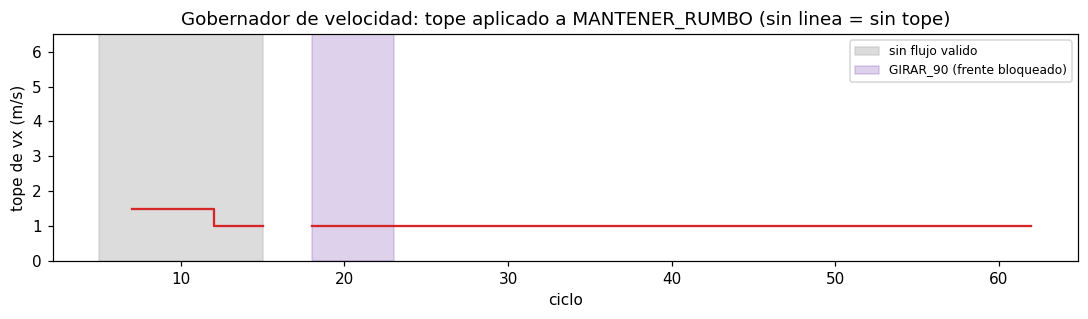

In [18]:
motor = _build_nodes(ClienteMudo())['motor']
filas = []
s = {'telemetry': estado(z=-10.0)['telemetry'], 'velocity_command': action_to_command('FRENAR'), 'next_action': 'FRENAR'}
for z in (-10.0, -9.8, -9.5, -9.0, -8.0):
    s['telemetry'] = estado(z=z)['telemetry']
    s['velocity_command'] = action_to_command('FRENAR')
    s = motor(s)
    filas.append({'z (m)': z, 'ancla (m)': s['_hover_alt_anchor'], 'vz comandada': round(s['velocity_command']['vz'], 3)})
display(pd.DataFrame(filas))

gov = SpeedGovernor()
seq = ([('flow', 0.0, False, 'MANTENER_RUMBO')] * 5 + [('degraded', 0.0, False, 'MANTENER_RUMBO')] * 10 +
       [('flow', 0.0, False, 'MANTENER_RUMBO')] * 3 + [('flow', 1.0, True, 'GIRAR_90')] * 5 +
       [('flow', 0.0, False, 'MANTENER_RUMBO')] * 60)
caps = [gov.update(*e) for e in seq]
fig, ax = plt.subplots(figsize=(10, 3))
ax.step(range(len(caps)), [np.nan if c is None else c for c in caps], where='post', color='#d62728')
ax.axvspan(5, 15, color='#bbb', alpha=0.5, label='sin flujo valido')
ax.axvspan(18, 23, color='#9467bd', alpha=0.3, label='GIRAR_90 (frente bloqueado)')
ax.set_xlabel('ciclo'); ax.set_ylabel('tope de vx (m/s)'); ax.legend(fontsize=8); ax.set_ylim(0, 6.5)
ax.set_title('Gobernador de velocidad: tope aplicado a MANTENER_RUMBO (sin linea = sin tope)')
plt.tight_layout(); plt.show()

## §9 — Replay de `navigate` sobre una corrida real de la v4

El registro JSONL de cada corrida guarda, por ciclo, el estado completo **después** del grafo, incluido el `ObstacleField` agregado por sector, el guiado y la telemetría. Eso permite reproducir la decisión ciclo a ciclo:

1. El estado de entrada del ciclo *k* es el estado de salida registrado del ciclo *k−1*, más las entradas nuevas del ciclo *k*: telemetría, guiado, waypoint activo y `ObstacleField`.
2. Se llama al `navigate_node` real con un `StallDetector` que acumula memoria a lo largo del replay, igual que en vuelo.
3. Se compara la ruta y la macro-acción reproducidas con las registradas.

El registro guarda el campo por sector, no por celda. Por eso el replay usa un `CampoRegistrado` que expone la misma API que `ObstacleField` (`sector_ttc`, `is_blocked`, `blocked_fraction`, `min_ttc`, `sector_occupancy`) con los valores del log, incluida la fracción bloqueada calculada en vuelo sobre las 9 celdas.

In [19]:
INF = float('inf')
class CampoRegistrado:
    # Misma API de consumo que ObstacleField, con los valores agregados del JSONL.
    def __init__(self, d):
        self.d = d or {}
        self.source = self.d.get('source', 'none')
        self.sec = self.d.get('sectors') or {}
    def sector_ttc(self, s):
        v = (self.sec.get(s) or {}).get('ttc_s'); return INF if v is None else float(v)
    def sector_occupancy(self, s): return float((self.sec.get(s) or {}).get('occupancy') or 0.0)
    def is_blocked(self, s): return bool((self.sec.get(s) or {}).get('blocked'))
    def blocked_fraction(self): return float(self.d.get('blocked_fraction') or 0.0)
    def min_ttc(self):
        v = self.d.get('min_ttc_s'); return INF if v is None else float(v)

ENTRADAS = ('telemetry', 'prev_telemetry', 'waypoint_guidance', 'target_waypoint', 'current_wp_index', 'waypoints', 'mission_completed')
PESADOS = ('rgb_image', 'prev_image', 'frame_history')

registros = [json.loads(l) for l in open(f'{RUN_STEM}.jsonl', encoding='utf-8')]
assert registros[0]['arm'] == G.AGENT_ARM, 'AGENT_ARM del kernel distinto del brazo de la corrida'
nav = _build_nodes(ClienteMudo())['navigate']
prev, filas = None, []
for r in registros:
    s = r['state']
    entrada = dict(prev) if prev else {}
    for k in ENTRADAS:
        if k in s:
            entrada[k] = s[k]
    entrada['obstacle_field'] = CampoRegistrado(s.get('obstacle_field'))
    out = nav(entrada)
    sec = (s.get('obstacle_field') or {}).get('sectors') or {}
    filas.append({'ciclo': r['cycle'], 't': r['t'], 'route_log': s.get('route'), 'route_replay': out.get('route'),
                  'accion_log': s.get('next_action'), 'accion_replay': out.get('next_action'),
                  'occ_izq': (sec.get('izquierda') or {}).get('occupancy'), 'occ_der': (sec.get('derecha') or {}).get('occupancy'),
                  'ttc_izq': (sec.get('izquierda') or {}).get('ttc_s'), 'ttc_der': (sec.get('derecha') or {}).get('ttc_s')})
    prev = {k: v for k, v in s.items() if k not in PESADOS}
rep = pd.DataFrame(filas)
rep['coincide'] = (rep.route_log == rep.route_replay) & (rep.accion_log == rep.accion_replay)
print(f"{len(rep)} ciclos; coincidencia de route y accion: {rep.coincide.mean():.2%}")
display(pd.crosstab(rep.route_log, rep.route_replay, margins=True))

1960 ciclos; coincidencia de route y accion: 99.13%


route_replay,evasive,girar_90,reactive,All
route_log,,,,
evasive,433,0,0,433
girar_90,0,19,0,19
reactive,0,0,1508,1508
All,433,19,1508,1960


In [20]:
dif = rep[~rep.coincide]
display(dif.groupby(['accion_log', 'accion_replay']).size().to_frame('ciclos'))
display(dif.head(8))
empate = dif[(dif.occ_izq == dif.occ_der)]
print(f'diferencias con ocupacion izquierda == derecha en el log (empate tras el redondeo a 3 decimales): {len(empate)} de {len(dif)}')

,,ciclos
accion_log,accion_replay,
EVADIR_DERECHA,EVADIR_IZQUIERDA,9
EVADIR_IZQUIERDA,EVADIR_DERECHA,8


,ciclo,t,route_log,route_replay,accion_log,accion_replay,occ_izq,occ_der,ttc_izq,ttc_der,coincide
373,374,92.694,evasive,evasive,EVADIR_DERECHA,EVADIR_IZQUIERDA,0.019,0.019,5.34,1.05,False
374,375,92.917,evasive,evasive,EVADIR_DERECHA,EVADIR_IZQUIERDA,0.019,0.019,5.06,0.76,False
375,376,93.068,evasive,evasive,EVADIR_DERECHA,EVADIR_IZQUIERDA,0.019,0.019,5.15,0.86,False
376,377,93.278,evasive,evasive,EVADIR_DERECHA,EVADIR_IZQUIERDA,0.019,0.019,5.14,0.85,False
1164,1165,288.591,evasive,evasive,EVADIR_IZQUIERDA,EVADIR_DERECHA,0.002,0.002,2.93,18.71,False
1165,1166,288.943,evasive,evasive,EVADIR_IZQUIERDA,EVADIR_DERECHA,0.002,0.002,2.60,18.37,False
1166,1167,289.107,evasive,evasive,EVADIR_IZQUIERDA,EVADIR_DERECHA,0.002,0.002,2.62,18.40,False
1167,1168,289.301,evasive,evasive,EVADIR_IZQUIERDA,EVADIR_DERECHA,0.002,0.002,2.74,18.52,False


diferencias con ocupacion izquierda == derecha en el log (empate tras el redondeo a 3 decimales): 17 de 17


**Por qué difiere lo que difiere.** Las diferencias son la elección del lado de una evasión (`EVADIR_IZQUIERDA` frente a `EVADIR_DERECHA`) cuando las ocupaciones de los dos sectores **empatan en el log**. `ObstacleField.to_dict()` redondea la ocupación a 3 decimales. En vuelo `evasive_node` comparó valores sin redondear, y en el replay, al empatar, decide el TTC lateral. La ruta (`evasive`) coincide igual. Todo lo demás se reproduce exactamente: las reglas de `navigate` son una función determinista de lo que registra el log.

El replay sirve para auditar cualquier corrida: cambiando `RUN_DIR` en §0 por otra del mismo brazo (`slm`) se obtiene la misma tabla. En corridas con deadlocks aparecen además diferencias esperadas en la regla 1, porque este kernel resuelve los deadlocks con `blind` en lugar del barrido con profundidad.

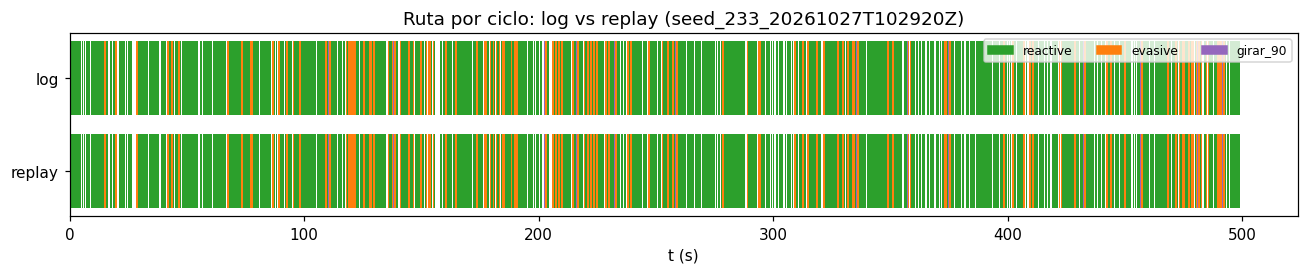

In [21]:
fig, ax = plt.subplots(figsize=(12, 2.6))
t0 = rep.t.iloc[0]
for nombre, col, y in (('log', 'route_log', 1), ('replay', 'route_replay', 0)):
    for _, r in rep.iterrows():
        ax.barh(y, 0.25, left=r.t - t0, color=colores.get(r[col], '#ccc'), height=0.8)
ax.set_yticks([0, 1], ['replay', 'log']); ax.set_xlabel('t (s)')
ax.legend(handles=[mpatches.Patch(color=c, label=k) for k, c in colores.items() if k in set(rep.route_log)], ncol=5, fontsize=8, loc='upper right')
ax.set_title(f'Ruta por ciclo: log vs replay ({RUN_DIR.name})')
plt.tight_layout(); plt.show()

## §10 — Resumen

- El lazo rápido es un `StateGraph` de cuatro nodos más el hover degradado. Toda la decisión está en `navigate`: 8 reglas en un orden que es la política.
- `perception` reduce dos fotogramas a 9 celdas con TTC en segundos reales, ocupación y confianza. Sin evidencia no inventa obstáculos, pero el gobernador de velocidad baja el crucero.
- La cinemática de cada macro-acción tiene una sola definición (`action_to_command`).
- La decisión registrada en las corridas v4 se reproduce desde el log con el código de vuelo (§9), lo que permite auditar ciclo por ciclo cualquier comportamiento del Capítulo 11.